# ISING 2D SIMULATIONS

## Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from numba import njit
from datetime import datetime

## Simulation parameters

In [2]:
TEMPERATURES = np.concatenate( (np.linspace(5, 2.8, 20, endpoint= False), np.linspace(2.8, 1.7386, 70, endpoint= False), np.linspace(1.7386, 0.5, 20)))

LENGTHS = np.array([8, 16, 32, 64, 128])

NUM_SEGUNDOS = 100_000

THERMAL_PERCENTAGE = 0.15
N_TERM = int(THERMAL_PERCENTAGE*NUM_SEGUNDOS)
N_MED = NUM_SEGUNDOS - N_TERM

TC_ISING = 2/np.log(1+np.sqrt(2))

LOAD_DATA = True
FITXER_DADES = 'dades_ising_20261119_0218.npz'

## Auxiliary functions

In [ ]:
def plotear(matriz):
    plt.matshow(matriz, cmap = 'gray')
    plt.show()


def calcular_energia(matriz):
    L = len(matriz)
    energia = 0 
    for i in range(L):
        for j in range(L):
            energia += matriz[i, j]*(matriz[(i+1)%L, j] +  matriz[i, (j+1)%L])

    return -energia

def calcular_magnetizacion(matriz):
    return np.sum(matriz)

@njit
def calculate_corr_esp(state):
    L = len(state)

    C = np.empty(L//2 + 1)

    for r in range(L//2 + 1):
        suma = 0.0
        for i in range(L):
            for j in range(L):
                suma += 0.5*state[i, j] * (state[(i+r)%L, j] + state[i, (j+r)%L])
        C[r] = suma/(L*L)
    return C



@njit
def metropolis_kernel(state, loop_exponentials, energy, magnetizacion, energy_vs_seg, magnetizacion_vs_seg, n_term, cada, C_acum):
    L = state.shape[0]
    num_segundos = energy_vs_seg.shape[0]
    n_mesures = 0

    for idx_segundo in range(1, num_segundos):
        i_eleg_vec = np.random.randint(0, L, size = L*L)
        j_eleg_vec = np.random.randint(0, L, size = L*L)
        for idx_iter in range(L*L):
            i_eleg = i_eleg_vec[idx_iter]
            j_eleg = j_eleg_vec[idx_iter]

            delta_energ_prop = 2*state[i_eleg,j_eleg]*(state[i_eleg-1,j_eleg] + state[(i_eleg+1)%L,j_eleg] + state[i_eleg,j_eleg-1] + state[i_eleg,(j_eleg+1)%L])

            if np.random.random() < loop_exponentials[delta_energ_prop//4 + 2]:
                state[i_eleg, j_eleg] *= -1
                energy += delta_energ_prop
                magnetizacion += 2*state[i_eleg, j_eleg]

        if cada > 0 and idx_segundo >= n_term and (idx_segundo - n_term) % cada == 0:
            C_acum += calculate_corr_esp(state)
            n_mesures += 1

        energy_vs_seg[idx_segundo] = energy
        magnetizacion_vs_seg[idx_segundo] = abs(magnetizacion)
    return energy, magnetizacion, n_mesures



def simular(T, L, NUM_SEGUNDOS, N_TERM, PLOTEAR, initial_state = None, cada = 0):
    # cada > 0: també mesura C(r) cada 'cada' passos després de termalitzar (cada = 0: no la mesura)
    rng = np.random.default_rng()
    N = L*L
    if initial_state is None:
        state = rng.choice([-1, 1], size = (L, L))
    else:
        state = initial_state.copy()

        

    energy = int(calcular_energia(state))
    magnetizacion = int(calcular_magnetizacion(state))


    energy_vs_seg = np.empty(NUM_SEGUNDOS)
    magnetizacion_vs_seg = np.empty(NUM_SEGUNDOS)

    energy_vs_seg[0] = energy
    magnetizacion_vs_seg[0] = np.abs(magnetizacion)

    # Acumulador de C(r), r = 0..L/2 (només s'omple si cada > 0)
    C_acum = np.zeros(L//2 + 1)

    loop_exponentials = np.exp(-np.array([-8, -4, 0, 4, 8]) / T)

    energy, magnetizacion, n_mesures = metropolis_kernel(state, loop_exponentials, energy, magnetizacion, energy_vs_seg, magnetizacion_vs_seg, N_TERM, cada, C_acum)


    if PLOTEAR:
        plt.plot(np.arange(NUM_SEGUNDOS), energy_vs_seg/N)
        plt.show()

    C = C_acum / n_mesures if n_mesures > 0 else None

    return energy_vs_seg[N_TERM:], magnetizacion_vs_seg[N_TERM:], state, C



def correlacion(x):
    x = np.asarray(x, dtype=float)
    m = len(x)
    xm = np.mean(x)
    sigma = np.std(x)
    x_norm = (x - xm) / sigma
    z = np.fft.irfft(np.abs(np.fft.rfft(x_norm, n=2*m))**2, n=2*m)
    rho = z[:m] / (m - np.arange(m))
    return rho

def calculate_tau(g_de_x_i):
    g_de_x_i = np.asarray(g_de_x_i, dtype=float)
    m = len(g_de_x_i)
    if np.std(g_de_x_i) == 0:
        return 0.0

    rho_g = correlacion(g_de_x_i)

    indices_bajos = np.where(rho_g[1:] <= 1e-3)[0] + 1
    k_max = indices_bajos[0] if len(indices_bajos) > 0 else m

    k = np.arange(1, k_max)
    tau_g = np.sum((1 - k / m) * rho_g[k])

    return tau_g


def line(x, a, slope):
    return a + slope * x


def interpolar_a_T(T0, temperatures, valors_vs_L_vs_T):
    return np.array([np.interp(T0, temperatures[::-1], valors[::-1]) for valors in valors_vs_L_vs_T])


def cada_per_L(L):
    return max(10, L)

## LOAD OR GENERATE DATA

In [ ]:
# Genera les dades o les carrega d'un fitxer, segons LOAD_DATA

if LOAD_DATA:
    d = np.load(FITXER_DADES)
    print('Claus disponibles:', d.files)

    energy_vs_L_vs_T_vs_seg = d['E']
    magnetizacion_vs_L_vs_T_vs_seg = d['M']

    TEMPERATURES = d['T']
    LENGTHS = d['L']
    NUM_SEGUNDOS = int(d['NUM_SEGUNDOS'])
    THERMAL_PERCENTAGE = float(d['THERMAL_PERCENTAGE'])
    N_TERM = int(d['N_TERM'])
    N_MED = energy_vs_L_vs_T_vs_seg.shape[2]

    if 'C' in d.files:
        C_vs_L_vs_T = d['C']
    else:
        C_vs_L_vs_T = None

else:
    energy_vs_L_vs_T_vs_seg = np.empty([len(LENGTHS), len(TEMPERATURES), N_MED])
    magnetizacion_vs_L_vs_T_vs_seg = np.empty_like(energy_vs_L_vs_T_vs_seg)

    C_vs_L_vs_T = np.full((len(LENGTHS), len(TEMPERATURES), LENGTHS.max()//2 + 1), np.nan)

    for idx_L, L in enumerate(LENGTHS):
        ult_estado = None
        for idx_T, T in enumerate(TEMPERATURES):
            print(f'L = {L}, T = {T}')

            # First T below tc seems to be better to begin ordered bc it's easier to thermalize
            if T < TC_ISING and (idx_T == 0 or TEMPERATURES[idx_T - 1] >= TC_ISING):
                ult_estado = np.ones((L, L), dtype=np.int64)
            energy_vs_L_vs_T_vs_seg[idx_L, idx_T], magnetizacion_vs_L_vs_T_vs_seg[idx_L, idx_T], ult_estado, C_vs_L_vs_T[idx_L, idx_T, :L//2 + 1] = simular(T, L, NUM_SEGUNDOS, N_TERM, False, ult_estado, cada_per_L(L))
            if idx_T in np.arange(1,6):
                plt.plot(np.arange(N_TERM, NUM_SEGUNDOS), energy_vs_L_vs_T_vs_seg[idx_L, idx_T]/(L*L), label = f'T = {T}')
        plt.title(f'Length = {L}')
        plt.show()
        plt.savefig('Energy_vs_MC_Step.png')




if not LOAD_DATA:
    fitxer_sortida = f"dades_ising_{datetime.now():%Y%m%d_%H%M}.npz"
    np.savez(
        fitxer_sortida,
        E=energy_vs_L_vs_T_vs_seg,
        M=magnetizacion_vs_L_vs_T_vs_seg,
        C=C_vs_L_vs_T,
        T=TEMPERATURES,
        L=LENGTHS,
        NUM_SEGUNDOS=NUM_SEGUNDOS,
        THERMAL_PERCENTAGE=THERMAL_PERCENTAGE,
        N_TERM=N_TERM,
    )

Claus disponibles: ['E', 'M', 'C', 'T', 'L', 'NUM_SEGUNDOS', 'THERMAL_PERCENTAGE', 'N_TERM']


## Correlation times to calculate errors

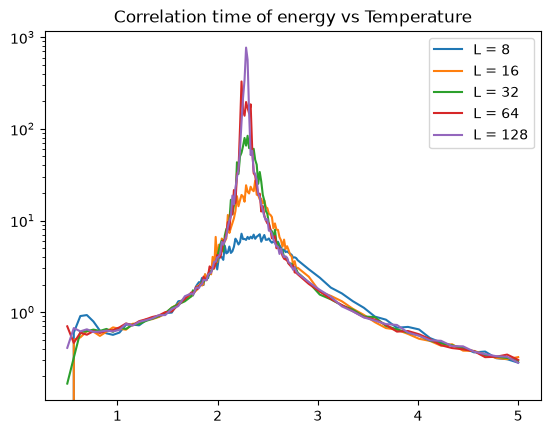

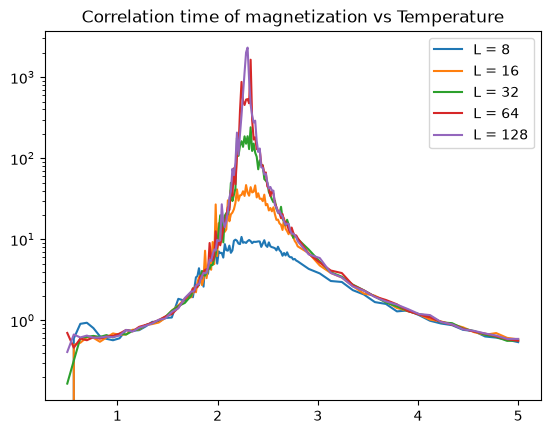

In [ ]:
tau_energy_vs_L_vs_T = np.zeros((len(LENGTHS), len(TEMPERATURES)))
tau_magnetization_vs_L_vs_T = np.zeros_like(tau_energy_vs_L_vs_T)
tau_magnetization2_vs_L_vs_T = np.zeros_like(tau_energy_vs_L_vs_T)
tau_Cv_vs_L_vs_T = np.zeros_like(tau_energy_vs_L_vs_T)
tau_chi_vs_L_vs_T = np.zeros_like(tau_energy_vs_L_vs_T)

for idx_L, L in enumerate(LENGTHS):
    for idx_T, T in enumerate(TEMPERATURES):
        tau_energy_vs_L_vs_T[idx_L, idx_T] = calculate_tau(energy_vs_L_vs_T_vs_seg[idx_L, idx_T])
        tau_magnetization_vs_L_vs_T[idx_L, idx_T] = calculate_tau(magnetizacion_vs_L_vs_T_vs_seg[idx_L, idx_T])
        tau_magnetization2_vs_L_vs_T[idx_L, idx_T] = calculate_tau(magnetizacion_vs_L_vs_T_vs_seg[idx_L, idx_T]**2)
        tau_Cv_vs_L_vs_T[idx_L, idx_T] = calculate_tau((energy_vs_L_vs_T_vs_seg[idx_L, idx_T] - np.mean(energy_vs_L_vs_T_vs_seg[idx_L, idx_T]))**2/T**2)
        tau_chi_vs_L_vs_T[idx_L, idx_T] = calculate_tau((magnetizacion_vs_L_vs_T_vs_seg[idx_L, idx_T] - np.mean(magnetizacion_vs_L_vs_T_vs_seg[idx_L, idx_T]))**2/T)


for idx_L, L in enumerate(LENGTHS):
    plt.plot(TEMPERATURES, tau_energy_vs_L_vs_T[idx_L], label = f'L = {L}')
plt.title('Correlation time of energy vs Temperature')
plt.yscale('log')
plt.legend()
plt.show()
plt.savefig('Correlation_time_of_energy_vs_temperature.png')


for idx_L, L in enumerate(LENGTHS):
    plt.plot(TEMPERATURES, tau_magnetization_vs_L_vs_T[idx_L], label = f'L = {L}')
plt.title('Correlation time of magnetization vs Temperature')
plt.yscale('log')
plt.legend()
plt.show()
plt.savefig('Correlation_time_of_magnetization_vs_temperature.png')



## Energy, Cv, M, chi vs T

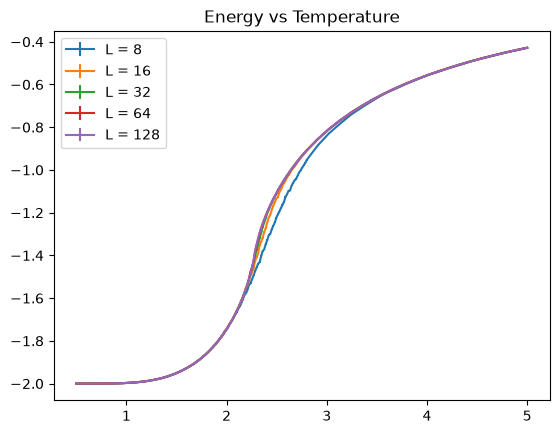

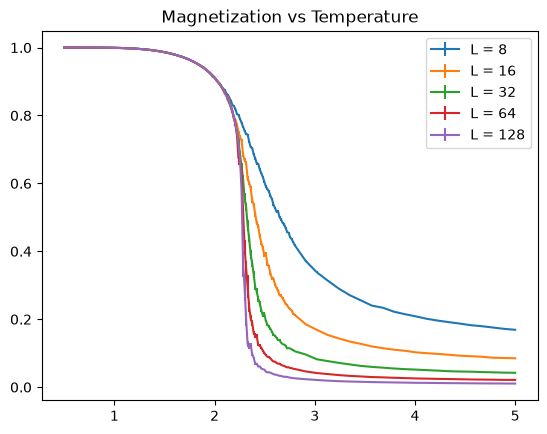

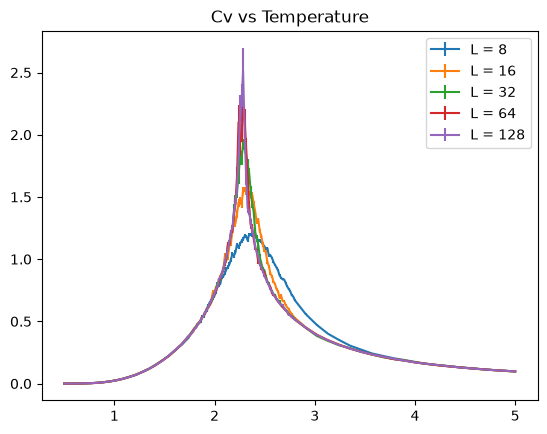

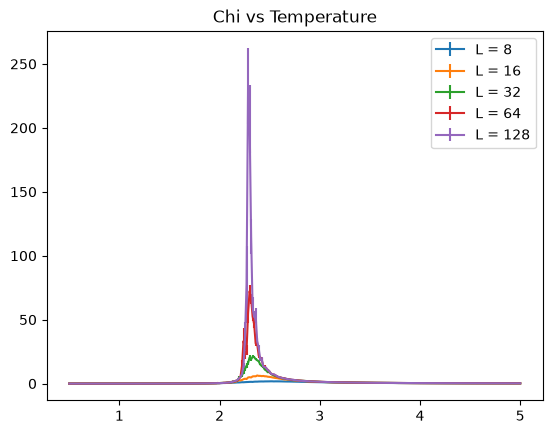

In [ ]:
observed_energy_vs_L_vs_T = np.empty((len(LENGTHS), len(TEMPERATURES)))
observed_Cv_vs_L_vs_T = np.empty_like(observed_energy_vs_L_vs_T)
observed_M_vs_L_vs_T = np.empty_like(observed_energy_vs_L_vs_T)
observed_M2_vs_L_vs_T = np.empty_like(observed_energy_vs_L_vs_T)
observed_chi_vs_L_vs_T = np.empty_like(observed_energy_vs_L_vs_T)
observed_magnetization4_vs_L_vs_T = np.empty_like(observed_energy_vs_L_vs_T)

errors_energy_vs_L_vs_T = np.empty_like(observed_energy_vs_L_vs_T)
errors_magnetization_vs_L_vs_T = np.empty_like(observed_energy_vs_L_vs_T)
errors_Cv_vs_L_vs_T = np.empty_like(observed_energy_vs_L_vs_T)
errors_chi_vs_L_vs_T = np.empty_like(observed_energy_vs_L_vs_T)

for idx_L, L in enumerate(LENGTHS):
    for idx_T, T in enumerate(TEMPERATURES):

        E = energy_vs_L_vs_T_vs_seg[idx_L, idx_T]
        M = magnetizacion_vs_L_vs_T_vs_seg[idx_L, idx_T]
        n_mesures = len(E)

        # means of measures
        observed_energy_vs_L_vs_T[idx_L, idx_T] = np.mean(E)
        observed_M_vs_L_vs_T[idx_L, idx_T] = np.mean(M)
        observed_M2_vs_L_vs_T[idx_L, idx_T] = np.mean(M**2)
        observed_magnetization4_vs_L_vs_T[idx_L, idx_T] = np.mean(M**4)
        observed_Cv_vs_L_vs_T[idx_L, idx_T] = np.mean((E - observed_energy_vs_L_vs_T[idx_L, idx_T])**2/T**2)
        observed_chi_vs_L_vs_T[idx_L, idx_T] = np.mean((M - observed_M_vs_L_vs_T[idx_L, idx_T])**2/T)


        # Errors
        errors_energy_vs_L_vs_T[idx_L, idx_T] = np.sqrt( np.var(E)/n_mesures*(2*tau_energy_vs_L_vs_T[idx_L, idx_T]+1) )
        errors_magnetization_vs_L_vs_T[idx_L, idx_T] = np.sqrt( np.var(M)/n_mesures*(2*tau_magnetization_vs_L_vs_T[idx_L, idx_T]+1) )
        errors_Cv_vs_L_vs_T[idx_L, idx_T] = np.sqrt( np.var((E - observed_energy_vs_L_vs_T[idx_L, idx_T])**2/T**2)/n_mesures*(2*tau_Cv_vs_L_vs_T[idx_L, idx_T]+1) )
        errors_chi_vs_L_vs_T[idx_L, idx_T] = np.sqrt( np.var((M - observed_M_vs_L_vs_T[idx_L, idx_T])**2/T)/n_mesures*(2*tau_chi_vs_L_vs_T[idx_L, idx_T]+1) )




for idx_L, L in enumerate(LENGTHS):
    plt.errorbar(TEMPERATURES, observed_energy_vs_L_vs_T[idx_L] / (L * L), yerr=errors_energy_vs_L_vs_T[idx_L] / (L * L), label=f'L = {L}')
plt.title('Energy vs Temperature')
plt.legend()
plt.show()
plt.savefig('energy_vs_temperature.png')

for idx_L, L in enumerate(LENGTHS):
    plt.errorbar(TEMPERATURES, observed_M_vs_L_vs_T[idx_L] / (L * L), yerr=errors_magnetization_vs_L_vs_T[idx_L] / (L * L), label=f'L = {L}')
plt.title('Magnetization vs Temperature')
plt.legend()
plt.show()
plt.savefig('magnetization_vs_temperature.png')

for idx_L, L in enumerate(LENGTHS):
    plt.errorbar(TEMPERATURES, observed_Cv_vs_L_vs_T[idx_L] / (L * L), yerr=errors_Cv_vs_L_vs_T[idx_L] / (L * L), label=f'L = {L}')
plt.title('Cv vs Temperature')
plt.legend()
plt.show()
plt.savefig('cv_vs_temperature.png')


for idx_L, L in enumerate(LENGTHS):
    plt.errorbar(TEMPERATURES, observed_chi_vs_L_vs_T[idx_L] / (L * L), yerr=errors_chi_vs_L_vs_T[idx_L] / (L * L), label=f'L = {L}')
plt.title('Chi vs Temperature')
plt.legend()
plt.show()
plt.savefig('chi_vs_temperature.png')

## Critical temperature via cumulant

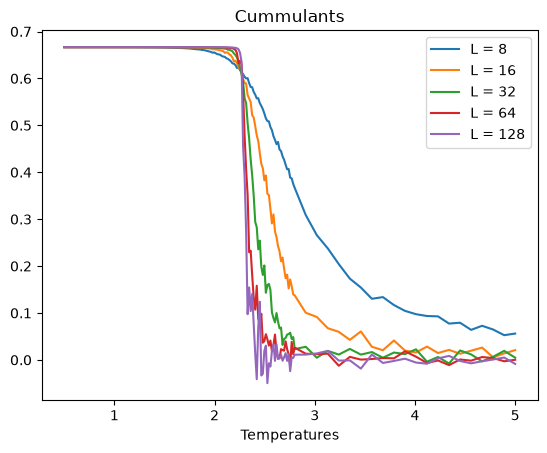

L=8 vs L=16: Tc ≈ 2.2745
L=8 vs L=32: Tc ≈ 2.2616
L=8 vs L=64: Tc ≈ 2.2741
L=8 vs L=128: Tc ≈ 2.2712
L=16 vs L=32: Tc ≈ 2.2575
L=16 vs L=64: Tc ≈ 2.2739
L=16 vs L=128: Tc ≈ 2.2709
L=32 vs L=64: Tc ≈ 2.2771
L=32 vs L=128: Tc ≈ 2.2718
L=64 vs L=128: Tc ≈ 2.2700
TC = 2.2702 +- 0.0018 vs TC_ising = 2.2692


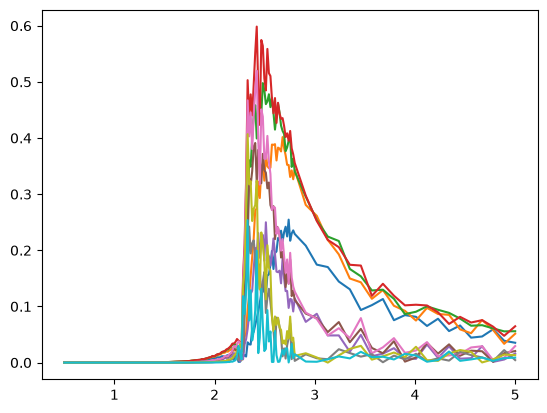

In [ ]:
cumulant = np.empty(( len(LENGTHS), len(TEMPERATURES) ))
for idx_L, L in enumerate(LENGTHS):
    for idx_T, T in enumerate(TEMPERATURES):
        cumulant[idx_L, idx_T] = 1- observed_magnetization4_vs_L_vs_T[idx_L, idx_T]/(3*observed_M2_vs_L_vs_T[idx_L, idx_T]**2)
    plt.plot(TEMPERATURES, cumulant[idx_L], label = f'L = {L}')
plt.title('Cummulants')
plt.legend()
plt.xlabel('Temperatures')
plt.show()
plt.savefig('Cummulants_vs_temperature.png')


n = len(LENGTHS)
n_pairs = n * (n - 1) // 2

differences = np.empty((n_pairs, len(TEMPERATURES)))
TC_cumm_dif = np.empty(n_pairs)
pair_labels = []

mask = (TEMPERATURES > 2) & (TEMPERATURES < 2.4)
T_win = TEMPERATURES[mask]

k = 0
for i in range(n):
    for j in range(i + 1, n):
        diff = cumulant[i] - cumulant[j]
        differences[k] = np.abs(diff)
        plt.plot(TEMPERATURES, differences[k], label=f'{LENGTHS[i]} - {LENGTHS[j]}')

        d = diff[mask]
        sign_change = np.where(np.diff(np.sign(d)) != 0)[0]
        if len(sign_change) > 0:
            a = sign_change[0]
            TC_cumm_dif[k] = T_win[a] - d[a] * (T_win[a+1] - T_win[a]) / (d[a+1] - d[a])
        else:
            TC_cumm_dif[k] = T_win[np.argmin(np.abs(d))]

        pair_labels.append((LENGTHS[i], LENGTHS[j]))
        print(f'L={LENGTHS[i]} vs L={LENGTHS[j]}: Tc ≈ {TC_cumm_dif[k]:.4f}')
        k += 1


TC_inf_est = np.mean(TC_cumm_dif)
error_TC_inf_est = np.std(TC_cumm_dif) / np.sqrt(n_pairs)
print(f'TC = {TC_inf_est:.4f} +- {error_TC_inf_est:.4f} vs TC_ising = {TC_ISING:.4f}')

## Calculate nu by fitting exponent of extrapolation to L--> infty

Nu: 0.9425 +- 0.0577


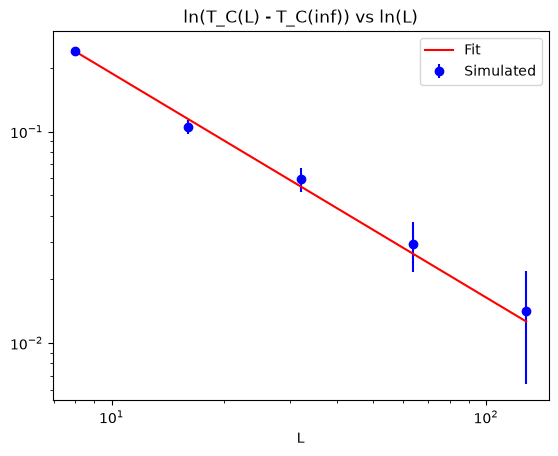

In [ ]:
# We first calculate TC(L) as the peak of chi and fit to get nu
# We essentially fit T_C(L) = T_C(inf) + K*L^(-1/nu)  --> ln(T_C(L) - T_C(inf)) = ln(K) -1/nu * ln(L)
DELTA_T_FI = np.abs(TEMPERATURES[21] - TEMPERATURES[20])
errors_TC_max = np.ones(len(LENGTHS))*DELTA_T_FI/2 # Errors are essentially resolution errors lol

idx_TC_max = np.array([np.argmax(observed_chi_vs_L_vs_T[idx_L]) for idx_L in range(len(LENGTHS))])
TC_max = TEMPERATURES[idx_TC_max]
dif_TC = np.abs(TC_max - TC_inf_est)
errors_dif_TC = np.sqrt(errors_TC_max**2 + error_TC_inf_est**2) #Error of Tc are resolution^2 + systematic^2


# Fit to get nu
popt, pcov = curve_fit(line, np.log(LENGTHS), np.log(dif_TC), sigma= errors_dif_TC / dif_TC, absolute_sigma=True, p0=[0, -1])
ln_K = popt[0]
slope = popt[1]
error_slope = np.sqrt(pcov[1,1])
nu = -1.0 / slope
error_nu = np.abs(error_slope/slope**2)
print(f"Nu: {nu:.4f} +- {error_nu:.4f}")

plt.title('ln(T_C(L) - T_C(inf)) vs ln(L)')
plt.errorbar(LENGTHS, dif_TC, yerr=errors_dif_TC, fmt='bo', label = 'Simulated')
plt.plot(LENGTHS, np.exp(ln_K) * (LENGTHS ** slope), 'r-', label='Fit')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('L')
plt.legend()
plt.show()
plt.savefig('log(TC(L)-TC_Ons)_vs_ln(L).png')

## Finite size effects to calculate beta/nu, gamma/nu

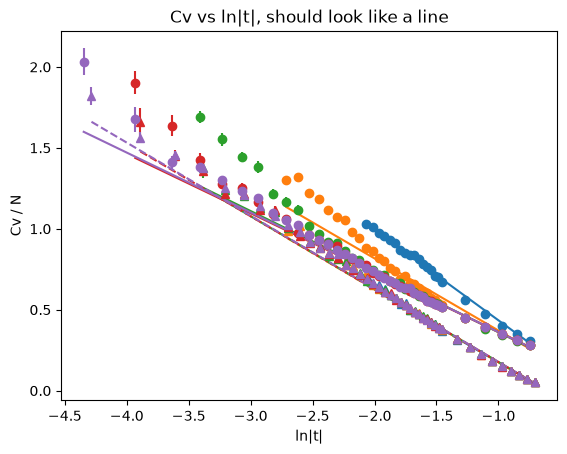

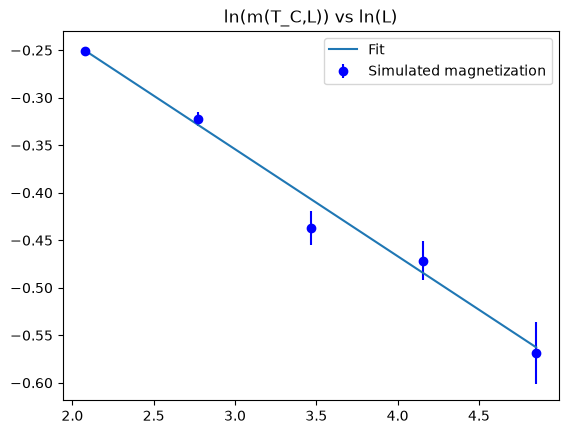

beta/nu = 0.1126 +- 0.0103 (exact: 0.125)
beta = 0.1061 +- 0.0117 (exact: 0.125)


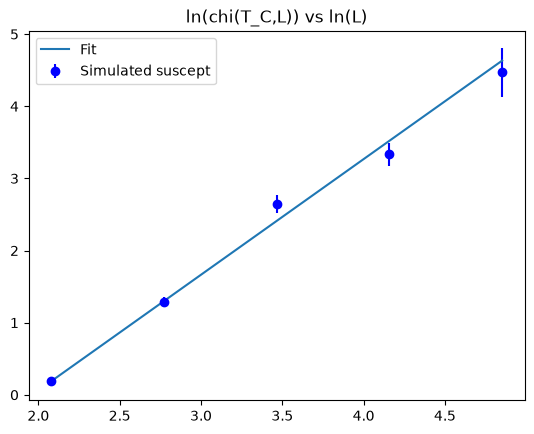

gamma/nu = 1.6031 +- 0.0586 (exact: 1.75)
gamma = 1.5110 +- 0.1077 (exact: 1.75)


In [ ]:
# We can't get alpha this way, so we're just gonna see if Cv fits a log (and hence we can take alpha = 0)
# Cv = A*np.log(tau) + B 
t = (TEMPERATURES - TC_inf_est) / TC_inf_est

for idx_L, L in enumerate(LENGTHS):
    # Mask of temperatures
    mask_plus = (t > 1/L) & (t < 0.5)
    mask_minus = (-t > 1/L) & (-t < 0.5)



    # Fit
    popt_plus, pcov_plus = curve_fit(line, np.log(t[mask_plus]), (observed_Cv_vs_L_vs_T[idx_L] / (L * L))[mask_plus], sigma= (errors_Cv_vs_L_vs_T[idx_L]/(L*L))[mask_plus], absolute_sigma=True)
    popt_minus, pcov_minus = curve_fit(line, np.log(-t[mask_minus]), (observed_Cv_vs_L_vs_T[idx_L] / (L * L))[mask_minus], sigma= (errors_Cv_vs_L_vs_T[idx_L]/(L*L))[mask_minus], absolute_sigma=True)

    color = plt.errorbar(np.log(t[mask_plus]), (observed_Cv_vs_L_vs_T[idx_L] / (L * L))[mask_plus], yerr=(errors_Cv_vs_L_vs_T[idx_L]/(L*L))[mask_plus], fmt='o', label=f'L = {L}, T > Tc')[0].get_color()
    plt.errorbar(np.log(-t[mask_minus]), (observed_Cv_vs_L_vs_T[idx_L] / (L * L))[mask_minus], yerr=(errors_Cv_vs_L_vs_T[idx_L]/(L*L))[mask_minus], fmt='^', color=color, label=f'L = {L}, T < Tc')
    plt.plot(np.log(t[mask_plus]), line(np.log(t[mask_plus]), *popt_plus), color=color)
    plt.plot(np.log(-t[mask_minus]), line(np.log(-t[mask_minus]), *popt_minus), '--', color=color)


plt.xlabel('ln|t|')
plt.ylabel('Cv / N')
plt.title('Cv vs ln|t|, should look like a line')
plt.show()
plt.savefig('Cv_vs_ln_t_should_line.png')




# BETA/NU
# We get beta by fitting ln(m(T_c, L)) = A -beta/nu * ln(L)
m_at_TC = interpolar_a_T(TC_inf_est, TEMPERATURES, observed_M_vs_L_vs_T) / (LENGTHS**2)
errors_m_at_TC = interpolar_a_T(TC_inf_est, TEMPERATURES, errors_magnetization_vs_L_vs_T) / (LENGTHS**2)

# fit with errors of ln(m(T_c, L)) which i interpolate
popt, pcov = curve_fit(line, np.log(LENGTHS), np.log(m_at_TC), sigma = errors_m_at_TC / m_at_TC, absolute_sigma=True, p0 = [1, -0.125])

plt.errorbar(np.log(LENGTHS), np.log(m_at_TC), yerr=errors_m_at_TC / m_at_TC, fmt='bo', label ='Simulated magnetization')
plt.plot(np.log(LENGTHS), line(np.log(LENGTHS), *popt), label = 'Fit')
plt.legend()
plt.title('ln(m(T_C,L)) vs ln(L)')
plt.show()
plt.savefig('ln(m(Tc))_vs_ln(L).png')

beta_sobre_nu = -popt[1]
error_stat_beta_sobre_nu = np.sqrt(pcov[1, 1])

# Tc has error which we implement by fitting m at Tc+-sigma_Tc and take avg of the slopes obtained 
pendents_desp = []
for T_desp in (TC_inf_est - error_TC_inf_est, TC_inf_est + error_TC_inf_est):
    m_desp = interpolar_a_T(T_desp, TEMPERATURES, observed_M_vs_L_vs_T) / (LENGTHS**2)
    errors_m_desp = interpolar_a_T(T_desp, TEMPERATURES, errors_magnetization_vs_L_vs_T) / (LENGTHS**2)
    popt_desp, _ = curve_fit(line, np.log(LENGTHS), np.log(m_desp), sigma = errors_m_desp / m_desp, absolute_sigma=True, p0 = [1, -0.125])
    pendents_desp.append(popt_desp[1])
error_sist_beta_sobre_nu = np.abs(pendents_desp[1] - pendents_desp[0])*0.5

# total error as quad sum: from fit of ln(m(Tc) (stat) and from ln(m(Tc+-sigma_Tc)) (system)
error_beta_sobre_nu = np.sqrt(error_stat_beta_sobre_nu**2 + error_sist_beta_sobre_nu**2)

beta = beta_sobre_nu*nu
error_beta = np.sqrt( (nu*error_beta_sobre_nu)**2 + (beta_sobre_nu*error_nu)**2 )

print(f'beta/nu = {beta_sobre_nu:.4f} +- {error_beta_sobre_nu:.4f} (exact: 0.125)')
print(f'beta = {beta:.4f} +- {error_beta:.4f} (exact: 0.125)')





# GAMMA/NU
# We get gamma by fitting ln(chi(T_c, L)) = A + gamma/nu * ln(L)
chi_at_TC = interpolar_a_T(TC_inf_est, TEMPERATURES, observed_chi_vs_L_vs_T) / (LENGTHS**2)
errors_chi_at_TC = interpolar_a_T(TC_inf_est, TEMPERATURES, errors_chi_vs_L_vs_T) / (LENGTHS**2)

popt, pcov = curve_fit(line, np.log(LENGTHS), np.log(chi_at_TC), sigma = errors_chi_at_TC / chi_at_TC, absolute_sigma=True, p0 = [1, 1.75])
plt.errorbar(np.log(LENGTHS), np.log(chi_at_TC), yerr=errors_chi_at_TC / chi_at_TC, fmt='bo', label ='Simulated suscept')
plt.plot(np.log(LENGTHS), line(np.log(LENGTHS), *popt), label = 'Fit')
plt.legend()
plt.title('ln(chi(T_C,L)) vs ln(L)')
plt.show()
plt.savefig('ln_chi_tc_vs_ln_L.png')

gamma_sobre_nu = popt[1]
error_stat_gamma_sobre_nu = np.sqrt(pcov[1, 1])

# Again as b4 for system error of Tc
pendents_desp = []
for T_desp in (TC_inf_est - error_TC_inf_est, TC_inf_est + error_TC_inf_est):
    chi_desp = interpolar_a_T(T_desp, TEMPERATURES, observed_chi_vs_L_vs_T) / (LENGTHS**2)
    errors_chi_desp = interpolar_a_T(T_desp, TEMPERATURES, errors_chi_vs_L_vs_T) / (LENGTHS**2)
    popt_desp, _ = curve_fit(line, np.log(LENGTHS), np.log(chi_desp), sigma = errors_chi_desp / chi_desp, absolute_sigma=True, p0 = [1, 1.75])
    pendents_desp.append(popt_desp[1])
error_sist_gamma_sobre_nu = np.abs(pendents_desp[1] - pendents_desp[0])*0.5

error_gamma_sobre_nu = np.sqrt(error_stat_gamma_sobre_nu**2 + error_sist_gamma_sobre_nu**2)
gamma = gamma_sobre_nu*nu
error_gamma = np.sqrt( (nu*error_gamma_sobre_nu)**2 + (gamma_sobre_nu*error_nu)**2 )

print(f'gamma/nu = {gamma_sobre_nu:.4f} +- {error_gamma_sobre_nu:.4f} (exact: 1.75)')
print(f'gamma = {gamma:.4f} +- {error_gamma:.4f} (exact: 1.75)')


## Critical exponents obtained via fitting of thermodynamic quantities

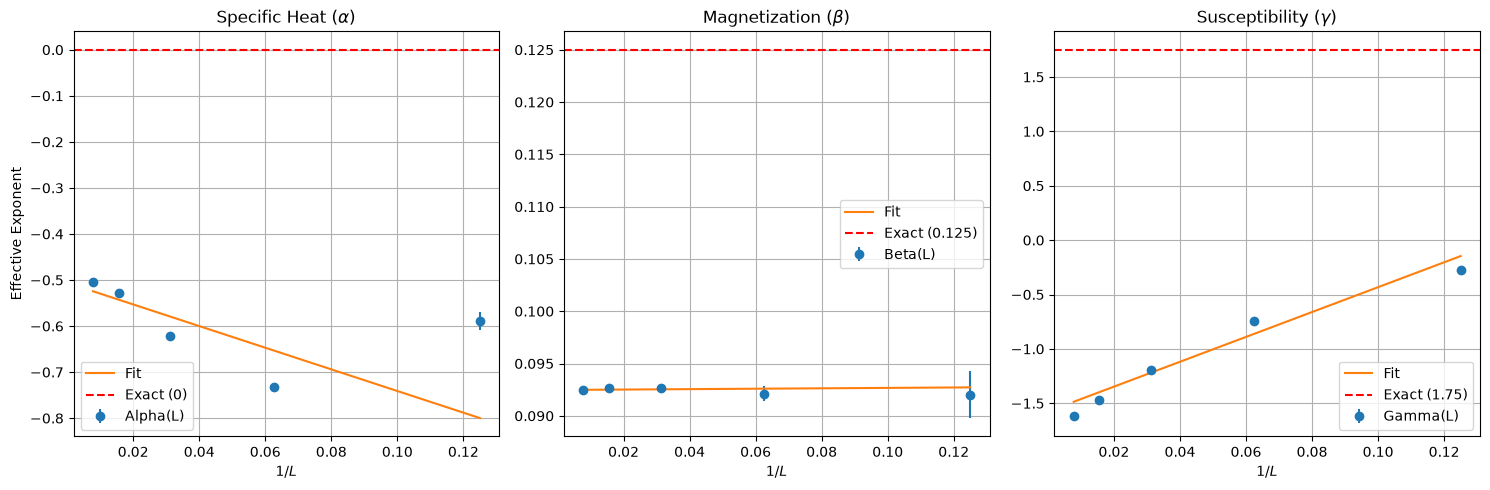

Alpha: 0.506 +- 0.004, expected 0
Beta: 0.092 +- 0.000, expected 0.125
Gamma: 1.575 +- 0.011, expected 1.75


In [ ]:
t = (TEMPERATURES - TC_ISING) / TC_ISING

alpha_vs_L = np.empty(len(LENGTHS))
error_alpha_vs_L = np.empty_like(alpha_vs_L)

beta_vs_L = np.empty(len(LENGTHS))
error_beta_vs_L = np.empty_like(beta_vs_L)

gamma_vs_L = np.empty(len(LENGTHS))
error_gamma_vs_L = np.empty_like(gamma_vs_L)

for idx_L, L in enumerate(LENGTHS):
    mask_plus = (1/L < t) & (t < 0.2)
    mask_minus = (1/L < -t) & (-t < 0.2)

    # alpha
    popt, pcov = curve_fit(line, np.log(t[mask_plus]), np.log(observed_Cv_vs_L_vs_T[idx_L][mask_plus]/(L*L)), sigma=(errors_Cv_vs_L_vs_T[idx_L][mask_plus]/observed_Cv_vs_L_vs_T[idx_L][mask_plus]), absolute_sigma=True)
    alpha_vs_L[idx_L] = popt[1]
    error_alpha_vs_L[idx_L] = np.sqrt(pcov[1,1])

    # beta
    popt, pcov = curve_fit(line, np.log(-t[mask_minus]), np.log(observed_M_vs_L_vs_T[idx_L][mask_minus]/(L*L)), sigma=(errors_magnetization_vs_L_vs_T[idx_L][mask_minus]/observed_M_vs_L_vs_T[idx_L][mask_minus]), absolute_sigma=True)
    beta_vs_L[idx_L] = popt[1]
    error_beta_vs_L[idx_L] = np.sqrt(pcov[1,1])

    # gamma
    popt, pcov = curve_fit(line, np.log(t[mask_plus]), np.log(observed_chi_vs_L_vs_T[idx_L][mask_plus]/(L*L)), sigma=(errors_chi_vs_L_vs_T[idx_L][mask_plus]/observed_chi_vs_L_vs_T[idx_L][mask_plus]), absolute_sigma=True)
    gamma_vs_L[idx_L] = popt[1]
    error_gamma_vs_L[idx_L] = np.sqrt(pcov[1,1])



# extrapolation
popt_alpha, pcov_alpha = curve_fit(line, 1/LENGTHS, alpha_vs_L, sigma=error_alpha_vs_L, absolute_sigma=True)
popt_beta, pcov_beta = curve_fit(line, 1/LENGTHS, beta_vs_L, sigma=error_beta_vs_L, absolute_sigma=True)
popt_gamma, pcov_gamma = curve_fit(line, 1/LENGTHS, gamma_vs_L, sigma=error_gamma_vs_L, absolute_sigma=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True)

axes[0].errorbar(1/LENGTHS, alpha_vs_L, yerr=error_alpha_vs_L, fmt='o', label='Alpha(L)')
axes[0].plot(1/LENGTHS, line(1/LENGTHS, *popt_alpha), '-', label='Fit')
axes[0].axhline(0.0, color='red', linestyle='--', label='Exact (0)')
axes[0].set_title(r'Specific Heat ($\alpha$)')
axes[0].set_xlabel(r'$1/L$')
axes[0].set_ylabel(r'Effective Exponent')
axes[0].legend()
axes[0].grid(True)

axes[1].errorbar(1/LENGTHS, beta_vs_L, yerr=error_beta_vs_L, fmt='o', label='Beta(L)')
axes[1].plot(1/LENGTHS, line(1/LENGTHS, *popt_beta), '-', label='Fit')
axes[1].axhline(0.125, color='red', linestyle='--', label='Exact (0.125)')
axes[1].set_title(r'Magnetization ($\beta$)')
axes[1].set_xlabel(r'$1/L$')
axes[1].legend()
axes[1].grid(True)

axes[2].errorbar(1/LENGTHS, gamma_vs_L, yerr=error_gamma_vs_L, fmt='o', label='Gamma(L)')
axes[2].plot(1/LENGTHS, line(1/LENGTHS, *popt_gamma), '-', label='Fit')
axes[2].axhline(1.75, color='red', linestyle='--', label='Exact (1.75)')
axes[2].set_title(r'Susceptibility ($\gamma$)')
axes[2].set_xlabel(r'$1/L$')
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()
plt.savefig('exponent_extrapolation.png')





print(f'Alpha: {-popt_alpha[0]:.3f} +- {np.sqrt(pcov_alpha[0,0]):.3f}, expected 0')
print(f'Beta: {popt_beta[0]:.3f} +- {np.sqrt(pcov_beta[0,0]):.3f}, expected 0.125')
print(f'Gamma: {-popt_gamma[0]:.3f} +- {np.sqrt(pcov_gamma[0,0]):.3f}, expected 1.75')

## Scaling

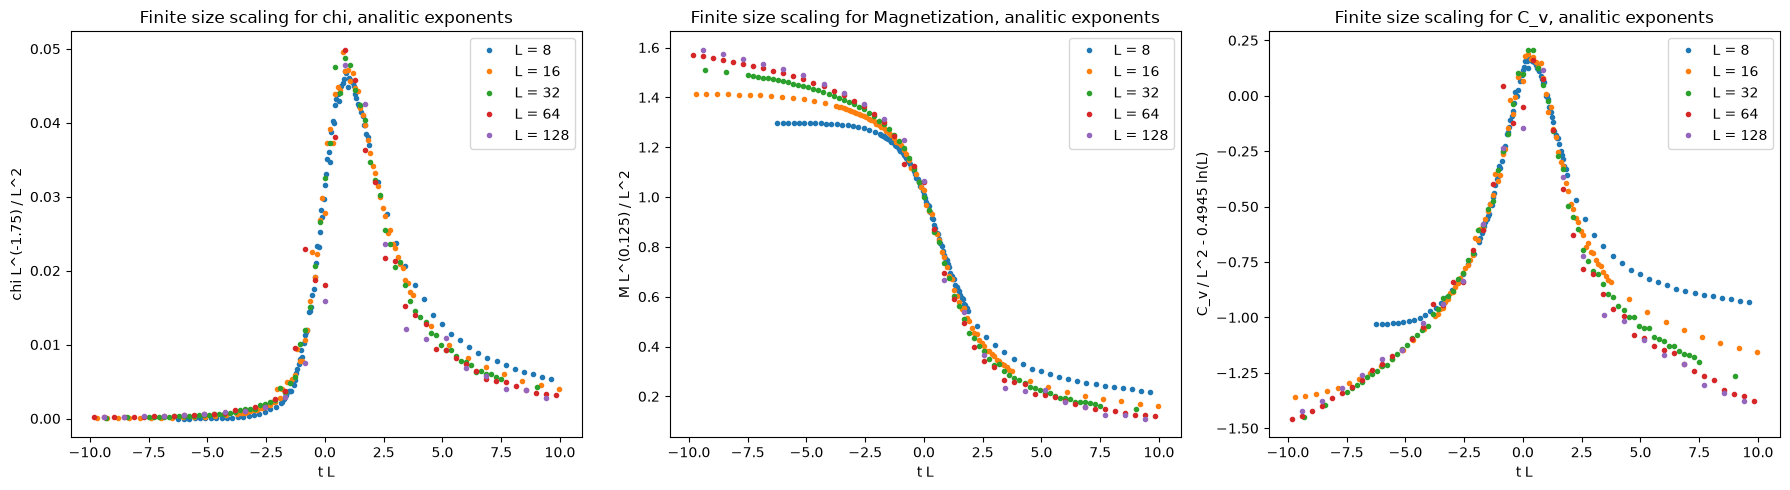

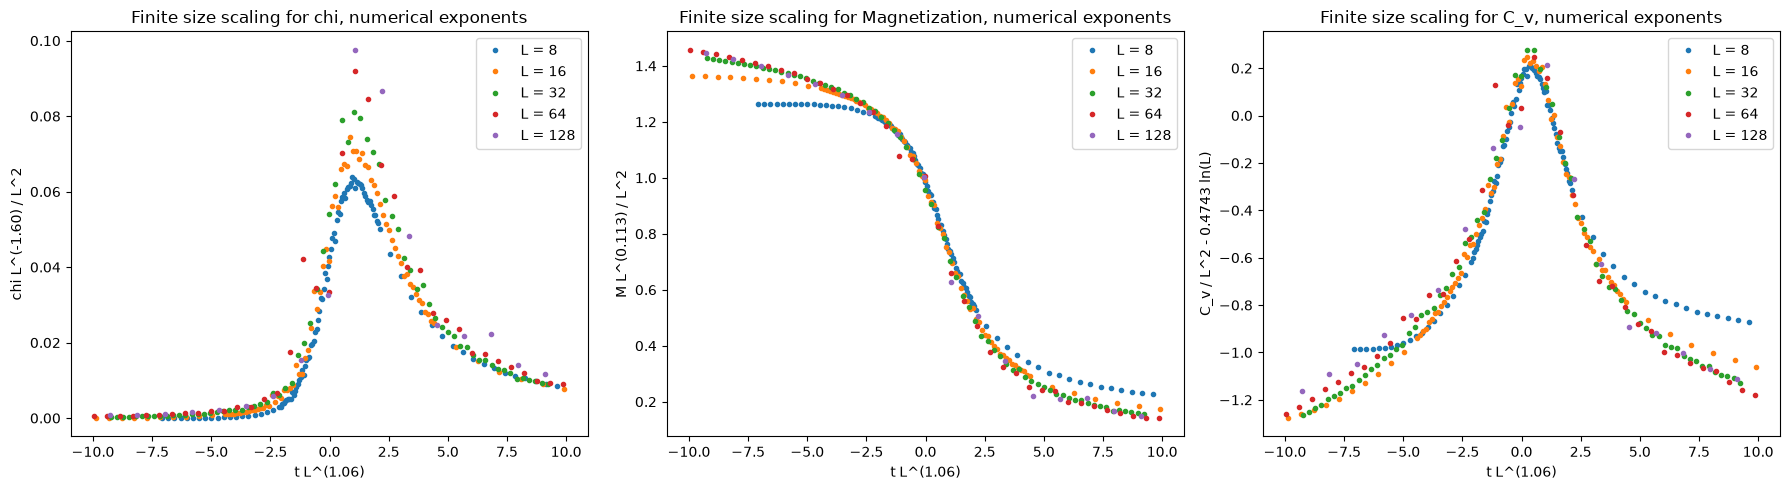

In [ ]:
A_EXACTA = 8 / (np.pi * TC_ISING**2)

Cv_max_per_spin = np.max(observed_Cv_vs_L_vs_T / LENGTHS[:, None]**2, axis=1)
popt_A, pcov_A = curve_fit(line, np.log(LENGTHS), Cv_max_per_spin)
A_num = popt_A[1]



# analitic expo
t_exacta = (TEMPERATURES - TC_ISING) / TC_ISING

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=False)

# chi
for idx_L, L in enumerate(LENGTHS):
    x = t_exacta * L
    mask = np.abs(x) < 10
    y = observed_chi_vs_L_vs_T[idx_L] * L**(-1.75) / (L * L)
    axes[0].plot(x[mask], y[mask], '.', label=f'L = {L}')
axes[0].set_title('Finite size scaling for chi, analitic exponents')
axes[0].set_xlabel('t L')
axes[0].set_ylabel('chi L^(-1.75) / L^2')
axes[0].legend()

# magnet
for idx_L, L in enumerate(LENGTHS):
    x = t_exacta * L
    mask = np.abs(x) < 10
    y = observed_M_vs_L_vs_T[idx_L] * L**(0.125) / (L * L)
    axes[1].plot(x[mask], y[mask], '.', label=f'L = {L}')
axes[1].set_title('Finite size scaling for Magnetization, analitic exponents')
axes[1].set_xlabel('t L')
axes[1].set_ylabel('M L^(0.125) / L^2')
axes[1].legend()

# Cv
for idx_L, L in enumerate(LENGTHS):
    x = t_exacta * L
    mask = np.abs(x) < 10
    y = observed_Cv_vs_L_vs_T[idx_L] / (L * L) - A_EXACTA * np.log(L)
    axes[2].plot(x[mask], y[mask], '.', label=f'L = {L}')
axes[2].set_title('Finite size scaling for C_v, analitic exponents')
axes[2].set_xlabel('t L')
axes[2].set_ylabel(f'C_v / L^2 - {A_EXACTA:.4f} ln(L)')
axes[2].legend()

plt.tight_layout()
plt.show()
plt.savefig('scaling_theoret.png')


# num expon
t = (TEMPERATURES - TC_inf_est) / TC_inf_est

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=False)

# chi
for idx_L, L in enumerate(LENGTHS):
    x = t * L**(1/nu)
    mask = np.abs(x) < 10
    y = observed_chi_vs_L_vs_T[idx_L] * L**(-gamma_sobre_nu) / (L * L)
    axes[0].plot(x[mask], y[mask], '.', label=f'L = {L}')
axes[0].set_title('Finite size scaling for chi, numerical exponents')
axes[0].set_xlabel(f't L^({1/nu:.2f})')
axes[0].set_ylabel(f'chi L^({-gamma_sobre_nu:.2f}) / L^2')
axes[0].legend()

# magnet
for idx_L, L in enumerate(LENGTHS):
    x = t * L**(1/nu)
    mask = np.abs(x) < 10
    y = observed_M_vs_L_vs_T[idx_L] * L**(beta_sobre_nu) / (L * L)
    axes[1].plot(x[mask], y[mask], '.', label=f'L = {L}')
axes[1].set_title('Finite size scaling for Magnetization, numerical exponents')
axes[1].set_xlabel(f't L^({1/nu:.2f})')
axes[1].set_ylabel(f'M L^({beta_sobre_nu:.3f}) / L^2')
axes[1].legend()

# Cv
for idx_L, L in enumerate(LENGTHS):
    x = t * L**(1/nu)
    mask = np.abs(x) < 10
    y = observed_Cv_vs_L_vs_T[idx_L] / (L * L) - A_num * np.log(L)
    axes[2].plot(x[mask], y[mask], '.', label=f'L = {L}')
axes[2].set_title('Finite size scaling for C_v, numerical exponents')
axes[2].set_xlabel(f't L^({1/nu:.2f})')
axes[2].set_ylabel(f'C_v / L^2 - {A_num:.4f} ln(L)')
axes[2].legend()

plt.tight_layout()
plt.show()
plt.savefig('scaling_numerical.png')

## Correlation length

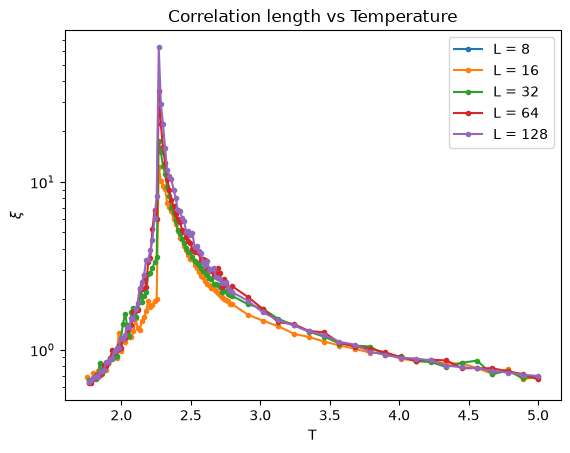

In [ ]:
R_MIN = 1
G_MIN_SOBRE = 2e-3
G_MIN_SOTA = 5e-4

xi_vs_L_vs_T = np.full((len(LENGTHS), len(TEMPERATURES)), np.nan)

for idx_L, L in enumerate(LENGTHS):
    r = np.arange(L // 2 + 1)
    for idx_T, T in enumerate(TEMPERATURES):
        C = C_vs_L_vs_T[idx_L, idx_T, : L // 2 + 1]

        if T < TC_ISING:
            m_abs = np.mean(magnetizacion_vs_L_vs_T_vs_seg[idx_L, idx_T, ::cada_per_L(L)]) / (L * L)
            G = C - m_abs**2
            G_MIN = G_MIN_SOTA
        else:
            G = C
            G_MIN = G_MIN_SOBRE

        # Primer r on G entra al soroll: a partir d'aquí ja no s'usa
        sota_soroll = np.where(G <= G_MIN)[0]
        r_tall = sota_soroll[0] if len(sota_soroll) > 0 else L // 2 + 1

        mask = (r >= R_MIN) & (r < r_tall) & (r <= L // 4) & (G > 0)

        if np.sum(mask) >= 3:
            try:
                popt, _ = curve_fit(line, r[mask], np.log(G[mask]))
                if popt[1] < 0:
                    xi_vs_L_vs_T[idx_L, idx_T] = -1.0 / popt[1]
            except RuntimeError:
                pass


for idx_L, L in enumerate(LENGTHS):
    plt.plot(TEMPERATURES, xi_vs_L_vs_T[idx_L], 'o-', ms=3, label=f'L = {L}')
plt.yscale('log')
plt.xlabel('T')
plt.ylabel(r'$\xi$')
plt.title('Correlation length vs Temperature')
plt.legend()
plt.show()
plt.savefig('Correlation_length_vs_temperature.png')